# CV story, part 2: ensembles, quality gate, smoothing (Stages D-F)

No new training. For three configs (final `dist_bootHL`, Stage B winner `mse_bootHL`, plain `mse` as baseline), per fold:

- **D** 3-seed ensemble (`evaluate.py --fold k --ckpt <3 seeds> --mc 20`) -> `cache/preds/ens_<config>_fold<k>.npz`
- **E** quality gate (`gate_report.py`): a per-window score; limit fitted on val, applied to test -> `cache/results/gate.csv`
- **F** every 2 s window of the val/test recordings (`predict_sequences.py`), then smoothing over time (`smooth_report.py`): median, Kalman + RTS, HMM (dist only); input gate before, output gate (posterior std) after; parameters tuned on val, scored on test -> `cache/results/smooth_ens_<config>_fold<k>.csv`

All test numbers below are means over the 5 test folds (each fold's subject-macro MAE), unless stated. Run `cv_selection.ipynb` first only if you want its keys in `values.json`; this notebook does not depend on it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from bpm.aggregate import BIN_EDGES, decide, ltgo_folds, macro, parse_tag, subject_mae

PREDS = ROOT / "cache" / "preds"
RESULTS = ROOT / "cache" / "results"
OUT = ROOT / "cache" / "deck" / "cv_story"   # figures + values.json for the deck
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ["multisite-ppg", "wrist-finger-ppg"]

## Style

Single source of truth for every plot below. Colors come from a colorblind-safe palette and are bound to **roles**: a config keeps its color in every figure of both notebooks. Plot cells never use a raw hex color or font size.

In [2]:
# palette of docs/hr_cnn_bilstm_results.odp (the deck these figures get merged into):
# ink #212a30, accent green #1e7f5c, red #b03a2e, secondary #555b60, muted #7a7f84, light #c9d1cd, card #edf2f0
COLORS = {
    # configs (role = model family): baselines slate/grey, MSE + boot red, dist + boot green
    "mse": "#212a30", "huber10": "#555b60", "mae": "#7a7f84",
    "mse_bootHL": "#b03a2e", "mse_bootHL_lds0.5": "#b03a2e", "mse_bootHL_lds1": "#b03a2e",
    "dist_bootHL": "#1e7f5c", "dist_bootHL_lds0.5": "#1e7f5c", "dist_bootHL_lds1": "#1e7f5c",
    # datasets
    "multisite-ppg": "#212a30", "wrist-finger-ppg": "#1e7f5c",
    # scores (line style separates the greys, see SCORE_LS)
    "score_std": "#1e7f5c", "score_mc": "#b03a2e", "score_spread": "#212a30",
    "prominence": "#7a7f84", "skew": "#7a7f84",
    # smoothers
    "raw": "#7a7f84", "median": "#555b60", "kalman": "#1e7f5c", "hmm": "#212a30",
    # signals
    "truth": "#212a30", "ideal": "#7a7f84", "bad": "#b03a2e", "good": "#1e7f5c", "neutral": "#c9d1cd",
    # ink and surface
    "text": "#212a30", "muted": "#7a7f84", "grid": "#e8ecea", "surface": "#ffffff",
}
SCORE_LS = {"score_std": "-", "score_mc": "-", "score_spread": "-", "prominence": "-", "skew": "--"}
# LDS power shown by marker (scatter) / line style (curves), so 3 hues cover all 9 configs
MARKERS = {"": "o", "lds0.5": "s", "lds1": "^"}
LINESTYLES = {"": "-", "lds0.5": "--", "lds1": ":"}
LABELS = {
    "mse": "MSE", "huber10": "Huber δ10", "mae": "MAE",
    "mse_bootHL": "MSE + boot", "mse_bootHL_lds0.5": "MSE + boot + LDS 0.5", "mse_bootHL_lds1": "MSE + boot + LDS 1",
    "dist_bootHL": "dist + boot", "dist_bootHL_lds0.5": "dist + boot + LDS 0.5", "dist_bootHL_lds1": "dist + boot + LDS 1",
}
STYLE = {"fig_w": 10, "row_h": 4.2, "dpi": 110, "save_dpi": 200, "font": 11, "title": 13,
         "lw": 1.8, "lw_thin": 1.0, "marker": 70, "alpha": 0.25}

plt.rcParams.update({
    "figure.dpi": STYLE["dpi"], "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "figure.constrained_layout.use": True,
    "font.size": STYLE["font"], "axes.titlesize": STYLE["title"], "axes.labelsize": STYLE["font"],
    "legend.fontsize": STYLE["font"] - 1, "legend.frameon": False,
    "text.color": COLORS["text"], "axes.labelcolor": COLORS["text"], "axes.edgecolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": STYLE["lw"],
    "font.family": "Lato",  # the deck's body font as rendered here (Calibri falls back to it)
})
from matplotlib.colors import LinearSegmentedColormap
DENSITY_CMAP = LinearSegmentedColormap.from_list("deck", ["#edf2f0", "#1e7f5c", "#212a30"])


def figsize(rows=1, w=None):
    return (w or STYLE["fig_w"], STYLE["row_h"] * rows)


def lds_of(cfg):
    return next((p for p in ("lds0.5", "lds1") if cfg.endswith(p)), "")


def save(fig, name):
    """Figure for the deck: cache/deck/cv_story/<name>.png."""
    fig.savefig(OUT / f"{name}.png", dpi=STYLE["save_dpi"], facecolor=COLORS["surface"])


VALUES_PATH = OUT / "values.json"
VALUES = json.loads(VALUES_PATH.read_text()) if VALUES_PATH.exists() else {}


def put(section, **kv):
    """Record numbers the deck cites (values.json, merged across both notebooks)."""
    conv = lambda v: v.item() if hasattr(v, "item") else v
    VALUES.setdefault(section, {}).update({k: conv(v) for k, v in kv.items()})
    VALUES_PATH.write_text(json.dumps(VALUES, indent=1, default=float))


BIN_LABELS = [f"{lo}-{hi}" if np.isfinite(hi) else f"{lo}+" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])]


def bin_of(truth):
    return pd.cut(truth, BIN_EDGES, right=False, labels=BIN_LABELS)

In [3]:
CFGS = ["dist_bootHL", "mse_bootHL", "mse"]


def load(tag, config, fold, seed):
    z = np.load(PREDS / f"{tag}.npz")
    d = pd.DataFrame({k: z[k] for k in ["subject", "split", "truth", "pred", "scores", "score_spread", "score_std", "score_mc"]})
    d["dataset"] = z["dataset_source"]
    d[["config", "fold", "seed"]] = config, fold, seed
    return d


E = pd.concat([load(f"ens_{c}_fold{k}", c, k, -1) for c in CFGS for k in range(5)], ignore_index=True)
S1 = pd.concat([load(f"{c}_fold{k}_seed{s}", c, k, s) for c in CFGS for k in range(5) for s in (42, 1, 2)], ignore_index=True)
for d in (E, S1):
    d["err"] = (d["pred"] - d["truth"]).abs()
print(len(E), "ensemble rows,", len(S1), "single-seed rows")
E.groupby("config")[["score_std", "score_spread", "score_mc"]].apply(lambda g: g.notna().mean()).round(2)

311184 ensemble rows, 933552 single-seed rows


,score_std,score_spread,score_mc
config,,,
dist_bootHL,1.0,1.0,1.0
mse,0.0,1.0,1.0
mse_bootHL,0.0,1.0,1.0


## D. Seed ensemble

Ensemble = combine the 3 seeds (reg: mean prediction, spread = std across seeds; dist: average of the softmax curves). Test MAE per fold, single seeds averaged vs the ensemble.

In [4]:
def fold_mae(d, by):
    t = d[d["split"] == "test"]
    s = subject_mae(t, by=by)
    return s.groupby(list(by))[["dataset", "mae"]].apply(macro)


single = fold_mae(S1, ("config", "fold", "seed")).groupby(["config", "fold"]).mean().unstack("fold")
ens = fold_mae(E, ("config", "fold")).unstack("fold")
D = pd.DataFrame({"single_seed": single.mean(1), "ensemble": ens.mean(1)}).loc[CFGS]
D["gain"] = D["single_seed"] - D["ensemble"]
put("ensemble", **{f"single_{c}": D.loc[c, "single_seed"] for c in CFGS}, **{f"ens_{c}": D.loc[c, "ensemble"] for c in CFGS},
    **{f"gain_{c}": D.loc[c, "gain"] for c in CFGS})
display(pd.concat({"single seed (mean of 3)": single, "ensemble": ens}).round(2))
D.round(3)

fold                                    0     1     2     3     4
                        config                                   
single seed (mean of 3) dist_bootHL  4.37  3.94  4.30  4.68  4.58
                        mse          4.88  4.18  4.93  4.53  4.68
                        mse_bootHL   5.00  4.57  5.01  5.03  5.25
ensemble                dist_bootHL  4.18  3.77  4.12  4.44  4.39
                        mse          4.68  4.02  4.80  4.34  4.48
                        mse_bootHL   4.81  4.41  4.76  4.87  5.08

,single_seed,ensemble,gain
config,,,
dist_bootHL,4.374,4.179,0.195
mse_bootHL,4.975,4.788,0.187
mse,4.637,4.463,0.174


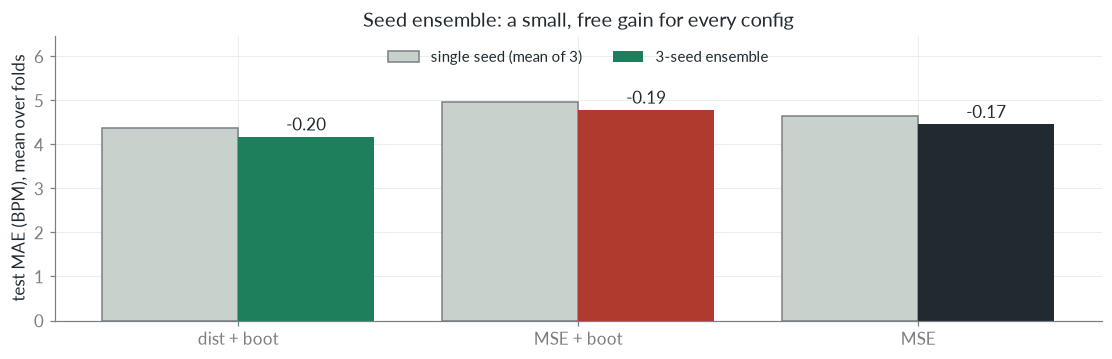

In [5]:
fig, ax = plt.subplots(figsize=figsize(0.75))
x = np.arange(len(CFGS))
ax.bar(x - 0.2, D["single_seed"], 0.4, color=COLORS["neutral"], edgecolor=COLORS["muted"], label="single seed (mean of 3)")
ax.bar(x + 0.2, D["ensemble"], 0.4, color=[COLORS[c] for c in CFGS], label="3-seed ensemble")
for xi, (c, r) in zip(x, D.iterrows()):
    ax.annotate(f"-{r['gain']:.2f}", (xi + 0.2, r["ensemble"]), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_xticks(x, [LABELS[c] for c in CFGS])
ax.set_ylabel("test MAE (BPM), mean over folds")
ax.set_ylim(0, D.values[:, :2].max() * 1.3)
ax.set_title("Seed ensemble: a small, free gain for every config")
ax.legend(loc="upper center", ncols=2)
save(fig, "ensemble")

## E. Quality gate

A score per window says how much to trust the prediction; windows above a limit are dropped. Scores:
- `score_std`: std of the dist head's softmax curve (dist only)
- `score_spread`: disagreement of the 3 seeds
- `score_mc`: std over 20 MC-dropout passes
- `prominence`, `skew`: signal-quality scores computed from the PPG window itself (no model)

**coverage** mode: limit = 90 % quantile of the val scores (keep 90 %). **mae** mode: loosest limit with val MAE ≤ 5 BPM; the val MAE of the ensembles is already below 5, so this mode keeps (almost) everything and is not shown further.
AURC = area under the risk-coverage curve (mean MAE over all coverage levels, lower = better ranking); ρ = Spearman(score, error).

In [6]:
G = pd.read_csv(RESULTS / "gate.csv")
Gc = G[G["mode"] == "coverage"]
agg = Gc.groupby(["config", "score"])[["test_coverage", "test_mae_all", "test_mae_passed", "test_aurc", "test_rho",
                                       "test_mae@80%", "test_mae@70%"]].mean()
print("mae-mode test coverage (mean):", G[G["mode"] == "mae"].groupby("config")["test_coverage"].mean().round(3).to_dict())
best = agg.loc["dist_bootHL"].sort_values("test_aurc").index[0]
put("gate", best_score=best, **{f"{c}_{s}_{m}": agg.loc[(c, s), m] for c, s in agg.index
                                for m in ["test_mae_all", "test_mae_passed", "test_aurc", "test_rho", "test_coverage", "test_mae@80%"]})
agg.round(3)

mae-mode test coverage (mean): {'dist_bootHL': 1.0, 'mse': 1.0, 'mse_bootHL': 0.943}


test_coverage  test_mae_all  test_mae_passed  \
config      score                                                        
dist_bootHL prominence            0.899         4.179            3.912   
            score_mc              0.893         4.179            3.473   
            score_spread          0.894         4.179            3.556   
            score_std             0.890         4.179            3.399   
            skew                  0.900         4.179            4.001   
mse         prominence            0.899         4.463            4.227   
            score_mc              0.886         4.463            4.420   
            score_spread          0.898         4.463            4.138   
            skew                  0.900         4.463            4.270   
mse_bootHL  prominence            0.899         4.788            4.484   
            score_mc              0.891         4.788            4.565   
            score_spread          0.898         4.788            4.343   
            skew                  0.900         4.788            4.580   

                          test_aurc  test_rho  test_mae@80%  test_mae@70%  
config      score                                                          
dist_bootHL prominence        2.715     0.559         3.612         3.246  
            score_mc          2.397     0.572         3.070         2.629  
            score_spread      2.710     0.533         3.209         2.837  
            score_std         1.855     0.707         2.818         2.100  
            skew              5.277     0.235         3.743         3.521  
mse         prominence        3.128     0.538         3.947         3.599  
            score_mc          4.228     0.253         4.252         4.179  
            score_spread      3.539     0.446         3.878         3.604  
            skew              5.484     0.239         4.018         3.772  
mse_bootHL  prominence        3.181     0.569         4.159         3.770  
            score_mc          4.439     0.270         4.430         4.382  
            score_spread      3.440     0.510         4.065         3.728  
            skew              5.867     0.252         4.303         4.033

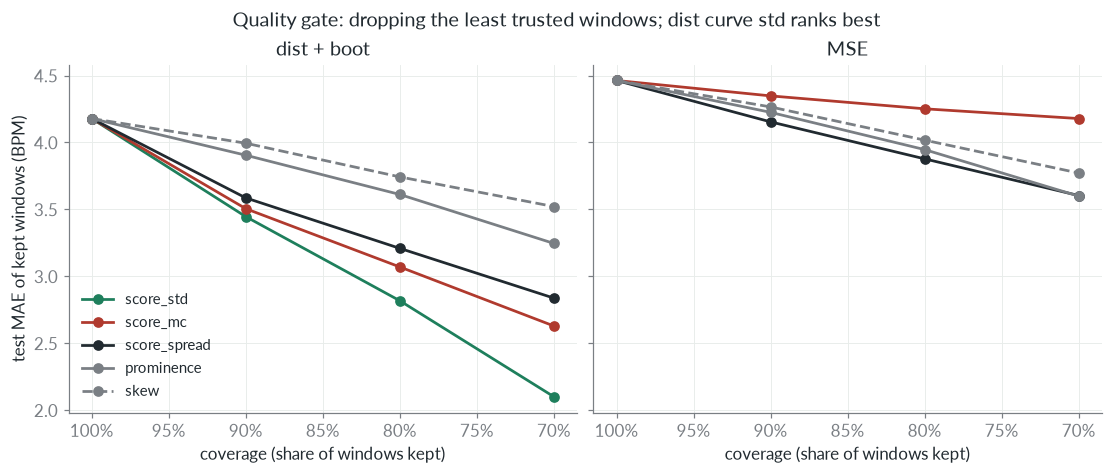

In [7]:
SCORES = ["score_std", "score_mc", "score_spread", "prominence", "skew"]
cov_cols = ["test_mae@100%", "test_mae@90%", "test_mae@80%", "test_mae@70%"]
cov_x = [1.0, 0.9, 0.8, 0.7]
fig, axes = plt.subplots(1, 2, figsize=figsize(1), sharey=True)
for ax, c in zip(axes, ["dist_bootHL", "mse"]):
    g = Gc[Gc["config"] == c].groupby("score")[cov_cols].mean()
    for s in SCORES:
        if s in g.index:
            ax.plot(cov_x, g.loc[s, cov_cols], marker="o", color=COLORS[s], ls=SCORE_LS[s], label=s)
    ax.invert_xaxis()
    ax.set_xlabel("coverage (share of windows kept)")
    ax.set_title(LABELS[c])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("test MAE of kept windows (BPM)")
axes[0].legend()
fig.suptitle("Quality gate: dropping the least trusted windows; dist curve std ranks best")
save(fig, "gate_curves")

,cov_40,cov_60,cov_70,cov_80,cov_90,cov_100,cov_110,cov_120,cov_130
score,,,,,,,,,
score_std,0.875,0.942,0.923,0.915,0.882,0.812,0.692,0.591,0.577
score_mc,0.868,0.925,0.930,0.923,0.886,0.780,0.658,0.535,0.619
prominence,0.956,0.965,0.923,0.892,0.864,0.828,0.801,0.768,0.877


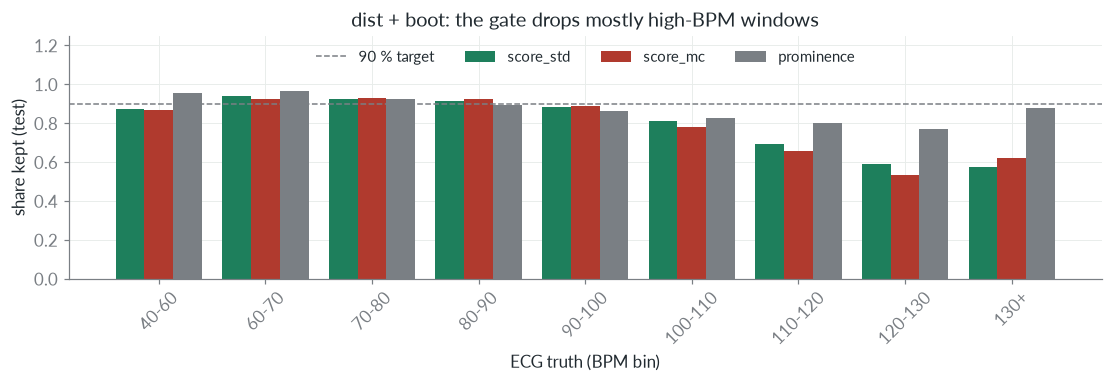

In [8]:
# where does the gate cut? coverage per BPM bin, coverage mode, dist_bootHL
bins_cov = [c for c in G.columns if c.startswith("cov_") and c[4:].isdigit()]
cb = Gc[Gc["config"] == "dist_bootHL"].groupby("score")[bins_cov].mean().loc[["score_std", "score_mc", "prominence"]]
fig, ax = plt.subplots(figsize=figsize(0.8))
x = np.arange(len(bins_cov))
for i, s in enumerate(cb.index):
    ax.bar(x + (i - 1) * 0.27, cb.loc[s], 0.27, color=COLORS[s], label=s)
ax.axhline(0.9, color=COLORS["muted"], ls="--", lw=STYLE["lw_thin"], label="90 % target")
ax.set_xticks(x, BIN_LABELS, rotation=45)
ax.set_ylim(0, 1.25)
ax.set_xlabel("ECG truth (BPM bin)"); ax.set_ylabel("share kept (test)")
ax.set_title("dist + boot: the gate drops mostly high-BPM windows")
ax.legend(loc="upper center", ncols=4)
save(fig, "gate_bins")
put("gate", **{f"cov_bin_{s}_{b}": cb.loc[s, b] for s in cb.index for b in bins_cov})
cb.round(3)

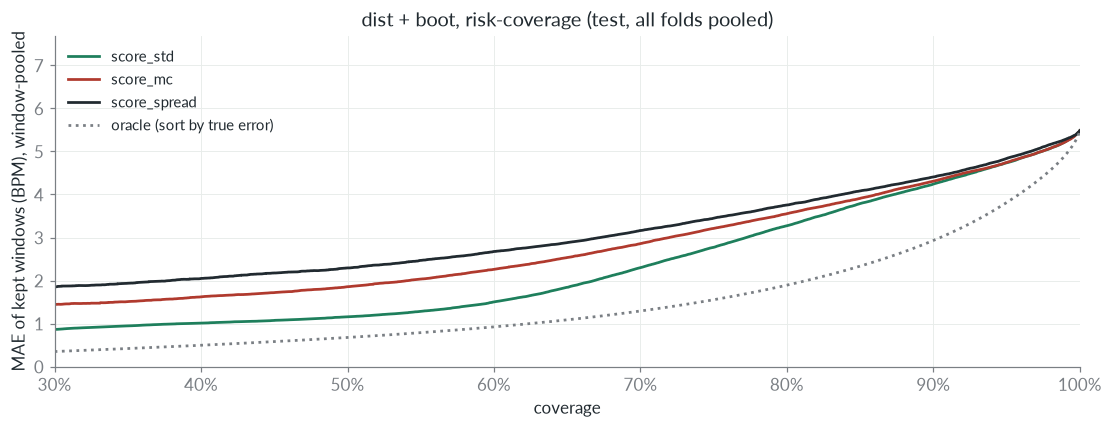

In [9]:
# pooled risk-coverage curves of the model scores (from the preds files), test windows of all folds
def risk_curve(score, err):
    o = np.argsort(score, kind="stable")
    e = np.asarray(err)[o]
    n = np.arange(1, len(e) + 1)
    return n / len(e), np.cumsum(e) / n


fig, ax = plt.subplots(figsize=figsize(0.9))
t = E[(E["split"] == "test") & (E["config"] == "dist_bootHL")]
for s in ["score_std", "score_mc", "score_spread"]:
    cov, risk = risk_curve(t[s].to_numpy(), t["err"].to_numpy())
    ax.plot(cov, risk, color=COLORS[s], label=s)
oracle = risk_curve(t["err"].to_numpy(), t["err"].to_numpy())
ax.plot(*oracle, color=COLORS["ideal"], ls=":", label="oracle (sort by true error)")
ax.set_xlim(0.3, 1); ax.set_ylim(0, None)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("coverage"); ax.set_ylabel("MAE of kept windows (BPM), window-pooled")
ax.set_title("dist + boot, risk-coverage (test, all folds pooled)")
ax.legend()
save(fig, "risk_coverage")

## F. Smoothing over time

Predictions every 2 s along each recording. Smoothers: running **median** (k windows), **Kalman + RTS** (random-walk HR, measurement noise from the window score, process noise from the train labels' step std), **HMM** over the 191 BPM bins (dist only, softmax as emission). Input gate: windows above the coverage limit get no weight (bridged if the gap ≤ 30 s). Output gate: drop windows whose posterior std is above the 90 % val quantile.

`smooth_report.py` scores every labelled window of the val/test recordings (not the ≤ 2000-per-subject cap of the preds files), so its "raw" MAE differs slightly from the ensemble MAE above.

In [10]:
F = pd.concat([pd.read_csv(p) for p in sorted(RESULTS.glob("smooth_ens_*.csv"))], ignore_index=True)
PIPES = [("raw", "none", "none", "raw"), ("raw", "coverage", "none", "raw + in gate"),
         ("median", "none", "none", "median"), ("kalman", "none", "none", "Kalman"),
         ("hmm", "none", "none", "HMM"), ("kalman", "coverage", "coverage", "Kalman + gates"),
         ("hmm", "coverage", "coverage", "HMM + gates")]
rows = []
for c in CFGS:
    for sm, ig, og, name in PIPES:
        f = F[(F["config"] == c) & (F["smoother"] == sm) & (F["in_gate"] == ig) & (F["out_gate"] == og)]
        if len(f):
            assert len(f) == 5, (c, name, len(f))
            rows.append({"config": c, "pipeline": name, "coverage": f["coverage"].mean(), "mae": f["mae_macro"].mean(),
                         "mae_sd": f["mae_macro"].std(), "lag_mae": f["lag_mae"].mean(),
                         "params": ", ".join(sorted(set(f["params"])))})
P = pd.DataFrame(rows).set_index(["config", "pipeline"])
put("smooth", **{f"{c}_{p}_{m}".replace(" ", "_").replace("+", "plus"): P.loc[(c, p), m]
                 for c, p in P.index for m in ["coverage", "mae", "mae_sd", "lag_mae"]})
P.round(3)

coverage    mae  mae_sd  lag_mae  \
config      pipeline                                           
dist_bootHL raw                1.000  4.106   0.272    7.973   
            raw + in gate      0.855  3.354   0.171    7.406   
            median             1.000  3.959   0.207    7.800   
            Kalman             1.000  3.687   0.202    7.857   
            HMM                1.000  3.708   0.193    7.722   
            Kalman + gates     0.864  3.065   0.172    6.292   
            HMM + gates        0.870  3.102   0.133    6.642   
mse_bootHL  raw                1.000  4.718   0.231    8.875   
            raw + in gate      0.868  4.286   0.188    8.702   
            median             1.000  4.575   0.222    8.902   
            Kalman             1.000  4.429   0.232    9.021   
            Kalman + gates     0.891  4.136   0.209    8.360   
mse         raw                1.000  4.399   0.292    8.691   
            raw + in gate      0.864  4.066   0.271    8.591   
            median             1.000  4.338   0.308    8.702   
            Kalman             1.000  4.253   0.281    8.670   
            Kalman + gates     0.896  3.971   0.279    8.439   

                                                                       params  
config      pipeline                                                           
dist_bootHL raw                                                            {}  
            raw + in gate                                                  {}  
            median                                         {'k': 5}, {'k': 9}  
            Kalman          {'m': 1, 'c': 0.5}, {'m': 1, 'c': 1}, {'m': 2,...  
            HMM                                            {'m': 2}, {'m': 4}  
            Kalman + gates  {'m': 1, 'c': 0.5}, {'m': 1, 'c': 1}, {'m': 2,...  
            HMM + gates                                    {'m': 2}, {'m': 4}  
mse_bootHL  raw                                                            {}  
            raw + in gate                                                  {}  
            median                              {'k': 15}, {'k': 5}, {'k': 9}  
            Kalman                         {'m': 1, 'c': 2}, {'m': 1, 'c': 4}  
            Kalman + gates  {'m': 1, 'c': 2}, {'m': 1, 'c': 4}, {'m': 2, '...  
mse         raw                                                            {}  
            raw + in gate                                                  {}  
            median                                         {'k': 5}, {'k': 9}  
            Kalman          {'m': 1, 'c': 1}, {'m': 1, 'c': 4}, {'m': 2, '...  
            Kalman + gates  {'m': 1, 'c': 1}, {'m': 1, 'c': 2}, {'m': 1, '...

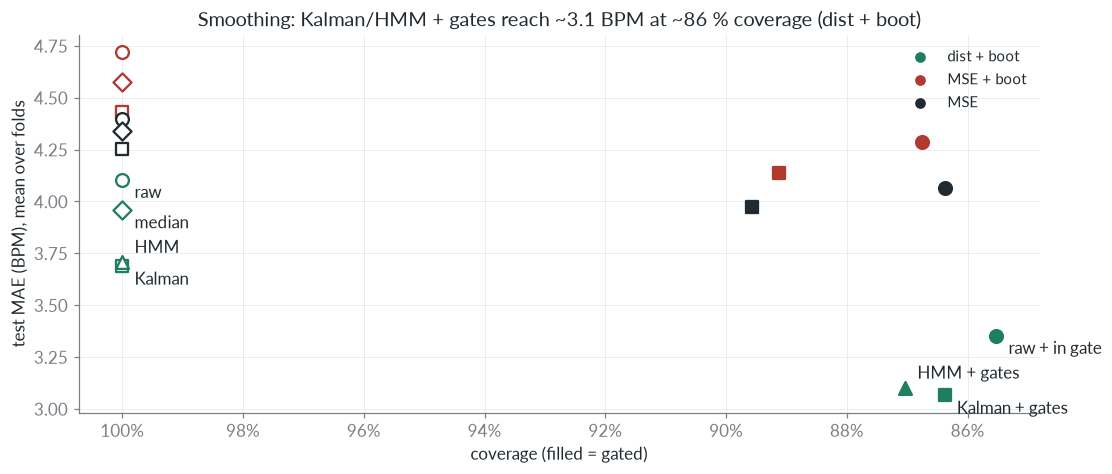

In [11]:
fig, ax = plt.subplots(figsize=figsize(1))
MK = {"raw": "o", "raw + in gate": "o", "median": "D", "Kalman": "s", "HMM": "^", "Kalman + gates": "s", "HMM + gates": "^"}
for c in CFGS:
    p = P.loc[c]
    ax.plot(p["coverage"], p["mae"], ls="none", color=COLORS[c], alpha=0.3)
    for name, r in p.iterrows():
        filled = "gate" in name
        ax.scatter(r["coverage"], r["mae"], s=STYLE["marker"], marker=MK[name], color=COLORS[c] if filled else COLORS["surface"],
                   edgecolor=COLORS[c], linewidth=1.5, zorder=3)
        if c == "dist_bootHL":
            dy = 6 if name.startswith("HMM") else -12  # HMM and Kalman sit on top of each other
            ax.annotate(name, (r["coverage"], r["mae"]), xytext=(8, dy), textcoords="offset points")
for c in CFGS:
    ax.scatter([], [], color=COLORS[c], label=LABELS[c])
ax.invert_xaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("coverage (filled = gated)"); ax.set_ylabel("test MAE (BPM), mean over folds")
ax.set_title("Smoothing: Kalman/HMM + gates reach ~3.1 BPM at ~86 % coverage (dist + boot)")
ax.legend(loc="upper right")
save(fig, "smooth_pareto")

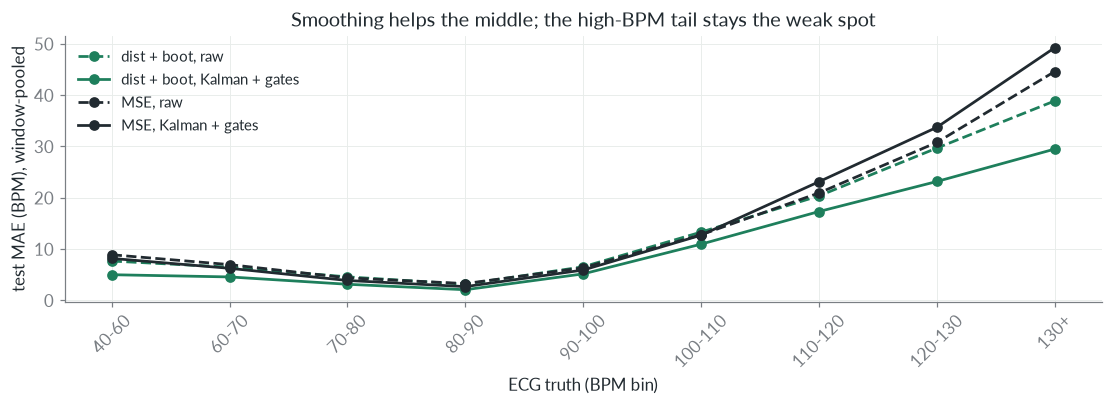

In [12]:
# per-bin test MAE: raw vs Kalman + gates
bcols = [f"mae_{lo}" for lo in BIN_EDGES[:-1]]
fig, ax = plt.subplots(figsize=figsize(0.85))
x = np.arange(len(bcols))
for c in ["dist_bootHL", "mse"]:
    for (sm, ig, og), ls, lab in [(("raw", "none", "none"), "--", "raw"), (("kalman", "coverage", "coverage"), "-", "Kalman + gates")]:
        f = F[(F["config"] == c) & (F["smoother"] == sm) & (F["in_gate"] == ig) & (F["out_gate"] == og)]
        ax.plot(x, f[bcols].mean(), ls=ls, marker="o", color=COLORS[c], label=f"{LABELS[c]}, {lab}")
ax.set_xticks(x, BIN_LABELS, rotation=45)
ax.set_xlabel("ECG truth (BPM bin)"); ax.set_ylabel("test MAE (BPM), window-pooled")
ax.set_title("Smoothing helps the middle; the high-BPM tail stays the weak spot")
ax.legend()
save(fig, "smooth_bins")

### Example recording

Re-runs the tuned Kalman + gates pipeline of one fold (same functions as `smooth_report.py`) on one test recording: the recording with the largest label range among the test recordings of fold 0. Shaded = windows dropped by the output gate.

In [13]:
from bpm.quality import fit_limit
from bpm.split import fold_split, load_folds
from smooth_report import FOLDS_PATH, labelled_rows, smooth, train_q

CFG, FOLD = "dist_bootHL", 0
seq_dir = ROOT / "cache" / "sequences" / f"ens_{CFG}_fold{FOLD}"
seqs = []
for p in sorted(seq_dir.glob("*.npz")):
    z = np.load(p)
    seqs.append({"name": p.stem, **{k: (z[k].item() if z[k].ndim == 0 else z[k]) for k in z.files}})
row = F[(F["config"] == CFG) & (F["fold"] == FOLD) & (F["smoother"] == "kalman") & (F["in_gate"] == "coverage") & (F["out_gate"] == "coverage")].iloc[0]
params = eval(row["params"])  # dict literal written by smooth_report
z = np.load(PREDS / f"ens_{CFG}_fold{FOLD}.npz")
v = z["split"] == "val"
in_limit = fit_limit(z["scores"][v], np.abs(z["pred"] - z["truth"])[v], z["subject"][v], z["dataset_source"][v])[0]
groups, _ = load_folds(FOLDS_PATH)
q = train_q(set(fold_split(groups, FOLD)["train"]))
res = [smooth(s, "kalman", params, in_limit, q, None, 30) for s in seqs]
val = labelled_rows(seqs, res, "val")
c = val["covered"]
out_limit = fit_limit(val["std"][c], val["err"][c], val["subject"][c], val["dataset"][c])[0]
test = labelled_rows(seqs, res, "test")
passed = test["covered"] & ~(test["std"] > out_limit)
from bpm.quality import balanced_mae
mae_check = balanced_mae(test["err"], test["subject"], test["dataset"], passed)[0]
print(f"params {params}, in_limit {in_limit:.3f}, out_limit {out_limit:.3f}; test MAE {mae_check:.3f} vs csv {row['mae_macro']:.3f}")
assert abs(mae_check - row["mae_macro"]) < 1e-6

q from 362 fold-train HR curves: multisite-ppg 1.006, wrist-finger-ppg 1.062


params {'m': 2, 'c': 0.5}, in_limit 16.205, out_limit 3.047; test MAE 2.970 vs csv 2.970


In [14]:
def rec_stats(seq, r):
    out, std, cov = r
    lab = np.isfinite(seq["label"])
    kept = lab & cov & ~(std > out_limit)
    e_raw = np.abs(seq["bpm"].astype(float) - seq["label"])[lab].mean()
    return lab.sum(), kept.sum() / max(lab.sum(), 1), e_raw, np.abs(out - seq["label"])[kept].mean()


# a recording that shows the gate at work: 300+ labelled windows, 70-95 % kept, raw MAE near the test mean,
# largest raw - (Kalman + gates) gain among those
cand = []
for i, (seq, r) in enumerate(zip(seqs, res)):
    if seq["split"] != "test":
        continue
    n, kept, e_raw, e_k = rec_stats(seq, r)
    if n >= 300 and 0.7 <= kept <= 0.95 and 3 <= e_raw <= 8:
        cand.append((e_raw - e_k, i))
assert cand, "no recording matches the example filter"
i = max(cand)[1]
s = seqs[i]
out, std, cov = res[i]
lab = np.isfinite(s["label"])
span = slice(max(np.flatnonzero(lab)[0] - 15, 0), np.flatnonzero(lab)[-1] + 15)  # labelled part +- 30 s
s = {k: (v[span] if isinstance(v, np.ndarray) and v.ndim and len(v) == len(lab) else v) for k, v in s.items()}
out, std, cov = out[span], std[span], cov[span]
tmin = s["idx"] * 2 / 60  # window index * 2 s stride -> minutes
gated = ~(cov & ~(std > out_limit))
fig, ax = plt.subplots(figsize=figsize(1.1))
for a, b in zip(*[np.flatnonzero(np.diff(np.r_[0, gated.astype(int), 0]) == d) for d in (1, -1)]):
    ax.axvspan(tmin[a], tmin[min(b, len(tmin) - 1)], color=COLORS["bad"], alpha=STYLE["alpha"], lw=0)
ax.plot(tmin, s["bpm"].astype(float), color=COLORS["raw"], lw=STYLE["lw_thin"], alpha=0.7, label="raw ensemble (every 2 s)")
ax.plot(tmin, out, color=COLORS["kalman"], label="Kalman + RTS")
ax.plot(tmin, s["label"], color=COLORS["truth"], lw=STYLE["lw_thin"], label="ECG truth")
ax.fill_between([], [], color=COLORS["bad"], alpha=STYLE["alpha"], label="dropped by gate")
lab = np.isfinite(s["label"])
e_raw = np.abs(s["bpm"].astype(float) - s["label"])[lab].mean()
e_k = np.abs(out - s["label"])[lab & ~gated].mean()
ax.set_xlabel("time in recording (min)"); ax.set_ylabel("BPM")
ax.set_title(f"{s['name']} ({s['dataset_source']}, test fold {FOLD}): raw MAE {e_raw:.1f}, Kalman + gates MAE {e_k:.1f} on {(~gated[lab]).mean():.0%} kept")
ax.legend(loc="upper left", ncols=2)
save(fig, "smooth_example")
put("smooth", example=s["name"], example_raw=e_raw, example_kalman=e_k)

/tmp/ipykernel_84039/3790561249.py:6: RuntimeWarning: Mean of empty slice
  return lab.sum(), kept.sum() / max(lab.sum(), 1), e_raw, np.abs(out - seq["label"])[kept].mean()
/var/home/julian/git/BSAA_HR/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## The whole pipeline in one number per step

dist + boot, test, mean over folds. Steps 1-2 from the capped preds files (Stage D), steps 3-6 from the smoothing report (all labelled windows).

In [15]:
c = "dist_bootHL"
steps = pd.DataFrame([
    ("single model", D.loc[c, "single_seed"], 1.0),
    ("3-seed ensemble", D.loc[c, "ensemble"], 1.0),
    ("ensemble, all windows", P.loc[(c, "raw"), "mae"], 1.0),
    ("+ Kalman smoothing", P.loc[(c, "Kalman"), "mae"], P.loc[(c, "Kalman"), "coverage"]),
    ("+ in/out gate", P.loc[(c, "Kalman + gates"), "mae"], P.loc[(c, "Kalman + gates"), "coverage"]),
], columns=["step", "mae", "coverage"])
fig, ax = plt.subplots(figsize=figsize(0.8))
x = np.arange(len(steps))
ax.bar(x, steps["mae"], color=[COLORS["neutral"]] * 2 + [COLORS[c]] * 3, edgecolor=COLORS["muted"])
for xi, r in steps.iterrows():
    ax.annotate(f"{r['mae']:.2f}" + (f"\n{r['coverage']:.0%} kept" if r["coverage"] < 0.999 else ""),
                (xi, r["mae"]), xytext=(0, 4), textcoords="offset points", ha="center")
ax.axvline(1.5, color=COLORS["muted"], ls=":", lw=STYLE["lw_thin"])
ax.set_xticks(x, steps["step"])
ax.set_ylim(0, steps["mae"].max() * 1.25)
ax.set_ylabel("test MAE (BPM)")
ax.set_title("dist + boot: from one model to the full pipeline")
save(fig, "pipeline_steps")
put("pipeline", **{r["step"]: r["mae"] for _, r in steps.iterrows()}, final_coverage=steps["coverage"].iloc[-1])
steps.round(3)

,step,mae,coverage
0,single model,4.374,1.000
1,3-seed ensemble,4.179,1.000
2,"ensemble, all windows",4.106,1.000
3,+ Kalman smoothing,3.687,1.000
4,+ in/out gate,3.065,0.864


In [16]:
print(json.dumps({k: VALUES[k] for k in ["ensemble", "pipeline"]}, indent=1, default=float))

{
 "ensemble": {
  "single_dist_bootHL": 4.374276638031006,
  "single_mse_bootHL": 4.974664211273193,
  "single_mse": 4.637143611907959,
  "ens_dist_bootHL": 4.178850173950195,
  "ens_mse_bootHL": 4.787924766540527,
  "ens_mse": 4.463318347930908,
  "gain_dist_bootHL": 0.19542646408081055,
  "gain_mse_bootHL": 0.18673944473266602,
  "gain_mse": 0.17382526397705078
 },
 "pipeline": {
  "single model": 4.374276638031006,
  "3-seed ensemble": 4.178850173950195,
  "ensemble, all windows": 4.105671425374737,
  "+ Kalman smoothing": 3.6872841120753455,
  "+ in/out gate": 3.0648783746037833,
  "final_coverage": 0.8638197292484359
 }
}
